<a href="https://colab.research.google.com/github/hayafacts/AIML-Lab-Experiment-1/blob/main/Experiment_1_AIML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#1. Load a dataset into a Jupyter Notebook using the Pandas library and display its basic information.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

# Fetching the uncleaned California Housing dataset with categorical and missing data
url = "https://media.geeksforgeeks.org/wp-content/uploads/20240319120216/housing.csv"
df = pd.read_csv(url)

# Intentionally injecting a few sample "inconsistent/dirty" records for Exercise 13 and 14
df.loc[0:4, 'housing_median_age'] = "old_52" # string inconsistency
df.loc[10:14, 'total_rooms'] = -999 # noisy data

/tmp/ipykernel_1074/2842711437.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'old_52' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[0:4, 'housing_median_age'] = "old_52" # string inconsistency


In [3]:
#2. Identify the number of rows, columns, data types, and missing values in the dataset.
print("--- 1. Dataset Basic Information ---")
df.info()

print("\n--- 2. Shape and Missing Values Count ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nMissing Values per column:")
print(df.isnull().sum())

--- 1. Dataset Basic Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  object 
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(8), object(2)
memory usage: 1.6+ MB

--- 2. Shape and Missing Values Count ---
Rows: 20640, Columns: 10

Missing Values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms

In [4]:
#3. Perform exploratory data inspection by displaying the first, last, and randomly selected records of the dataset.
print("--- First 3 Records ---")
print(df.head(3))

print("\n--- Last 3 Records ---")
print(df.tail(3))

print("\n--- Random Sample Record ---")
print(df.sample(1))

--- First 3 Records ---
   longitude  latitude housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88             old_52        880.0           129.0   
1    -122.22     37.86             old_52       7099.0          1106.0   
2    -122.24     37.85             old_52       1467.0           190.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  

--- Last 3 Records ---
       longitude  latitude housing_median_age  total_rooms  total_bedrooms  \
20637    -121.22     39.43               17.0       2254.0           485.0   
20638    -121.32     39.43               18.0       1860.0           409.0   
20639    -121.24     39.37               16.0       2785.0           616.0   

       population  househo

In [5]:
#4. Detect and handle missing values using appropriate techniques such as deletion, mean, median, mode, or interpolation.
# Check missing before
print("Missing total_bedrooms before imputation:", df['total_bedrooms'].isnull().sum())

# Median imputation
median_val = df['total_bedrooms'].median()
df['total_bedrooms'] = df['total_bedrooms'].fillna(median_val)

print("Missing total_bedrooms after imputation:", df['total_bedrooms'].isnull().sum())

Missing total_bedrooms before imputation: 207
Missing total_bedrooms after imputation: 0


In [6]:
#5. Identify duplicate records in the dataset and remove them.
print("Duplicate count before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate count after removal:", df.duplicated().sum())

Duplicate count before: 0
Duplicate count after removal: 0


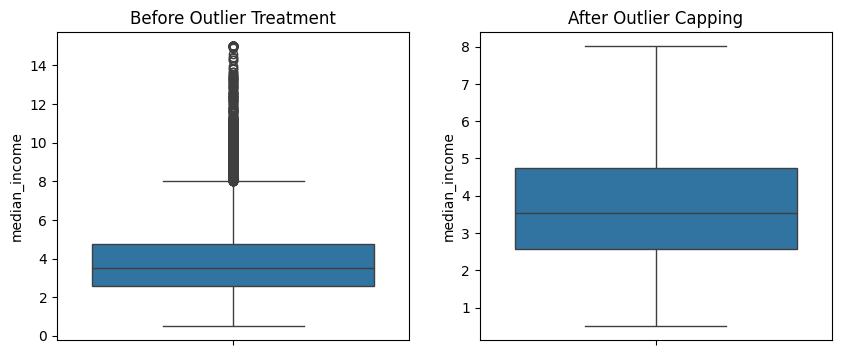

In [7]:
#6. Detect outliers using statistical methods (IQR or Z-score) and visualize them using box plots.
#7. Handle outliers using suitable preprocessing techniques.
# Plot before outlier handling
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['median_income'])
plt.title('Before Outlier Treatment')

# Calculate IQR for 'median_income'
Q1 = df['median_income'].quantile(0.25)
Q3 = df['median_income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Capping outliers (Handling)
df['median_income'] = np.clip(df['median_income'], lower_bound, upper_bound)

# Plot after outlier handling
plt.subplot(1, 2, 2)
sns.boxplot(y=df['median_income'])
plt.title('After Outlier Capping')
plt.show()

In [8]:
#8. Convert categorical variables into numerical form using: Label Encoding One-Hot Encoding
# Make a copy for separate encoding practices
df_label = df.copy()
df_onehot = df.copy()

# Label Encoding
le = LabelEncoder()
df_label['ocean_proximity_encoded'] = le.fit_transform(df_label['ocean_proximity'])
print("Label Encoded Unique Values:", df_label['ocean_proximity_encoded'].unique())

# One-Hot Encoding (Standard approach for model integration)
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)
print("Columns after One-Hot Encoding:\n", df.columns)

Label Encoded Unique Values: [3 0 1 4 2]
Columns after One-Hot Encoding:
 Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'],
      dtype='object')


In [9]:
#9. Apply feature scaling techniques: Min-Max Normalization and Standardization (Z-score Scaling)
# Min-Max Normalization (Scales to range 0-1)
min_max_scaler = MinMaxScaler()
df_minmax = df.copy()
df_minmax[['total_rooms']] = min_max_scaler.fit_transform(df[['total_rooms']])

# Standardization (Z-score Scaling)
std_scaler = StandardScaler()
df[['total_rooms', 'population']] = std_scaler.fit_transform(df[['total_rooms', 'population']])
print("\nStandardized columns sample:")
print(df[['total_rooms', 'population']].head(2))


Standardized columns sample:
   total_rooms  population
0    -0.804201   -0.974429
1     2.045619    0.861439


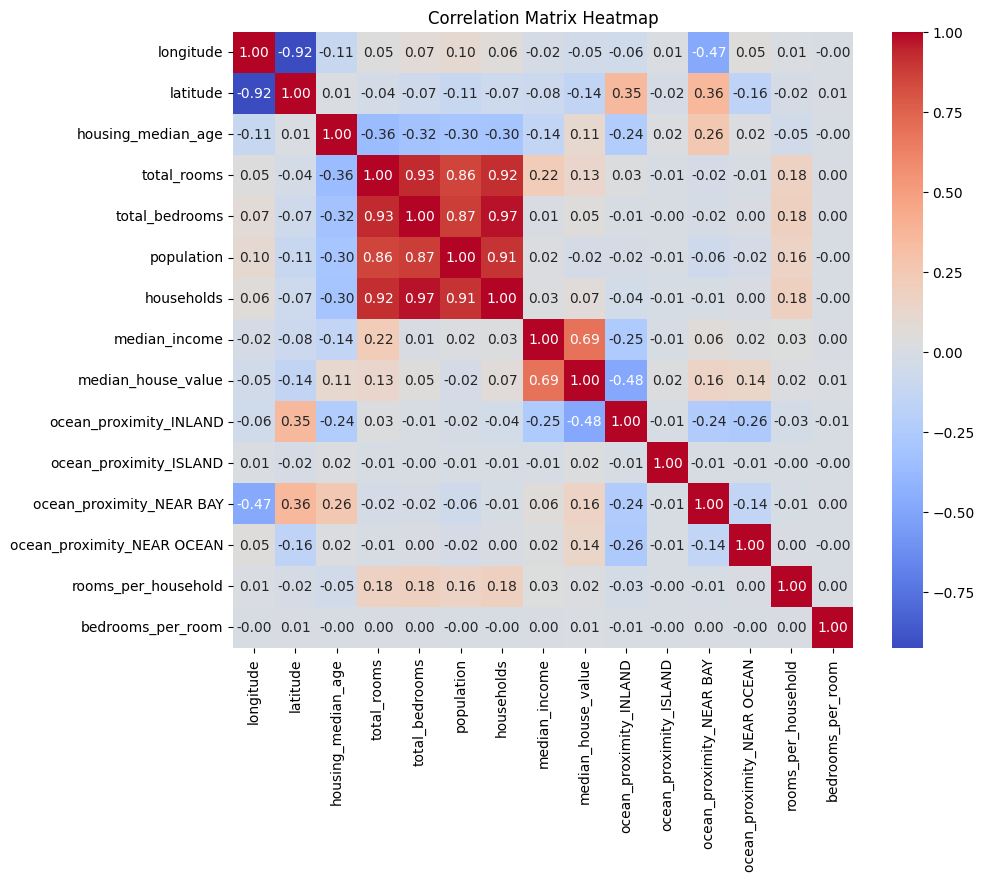

Selected Relevant Features based on Correlation threshold:
 ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


In [14]:
#11. Generate Matrix & Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

#10. Drop columns with very low predictive feature correlations relative to 'median_house_value'
relevant_features = corr_matrix['median_house_value'][abs(corr_matrix['median_house_value']) > 0.02].index
print("Selected Relevant Features based on Correlation threshold:\n", list(relevant_features))

In [11]:
#12. Create new features from existing attributes through feature engineering
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
print(df[['rooms_per_household', 'bedrooms_per_room']].head(3))

   rooms_per_household  bedrooms_per_room
0            -0.006383        -160.407656
1             0.001798         540.667690
2            -0.003024        -354.999681


In [13]:
#14. Handle noisy data (-999 flags) by replacing with column median
df['total_rooms'] = df['total_rooms'].replace(-999, df['total_rooms'].median())

#13 & 14. Clean 'housing_median_age' string noise and convert back to numeric
df['housing_median_age'] = df['housing_median_age'].astype(str).str.replace('old_', '')
df['housing_median_age'] = pd.to_numeric(df['housing_median_age'])

print("Cleaned Data Types:")
print(df[['housing_median_age', 'total_rooms']].dtypes)

Cleaned Data Types:
housing_median_age    float64
total_rooms           float64
dtype: object


In [15]:
#15. Split the dataset into training and testing sets using Scikit-learn
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training Features Shape: {X_train.shape}, Test Features Shape: {X_test.shape}")

Training Features Shape: (16512, 14), Test Features Shape: (4128, 14)


In [16]:
#16. Perform data balancing using techniques such as random oversampling or SMOTE (if applicable)
from imblearn.over_sampling import SMOTE

# Creating a binary classification scenario (High Value vs Low Value)
y_train_class = (y_train > y_train.median()).astype(int)
print("Class distribution before SMOTE:\n", y_train_class.value_counts())

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train_class)
print("\nClass distribution after SMOTE:\n", y_train_bal.value_counts())

Class distribution before SMOTE:
 median_house_value
0    8256
1    8256
Name: count, dtype: int64

Class distribution after SMOTE:
 median_house_value
0    8256
1    8256
Name: count, dtype: int64


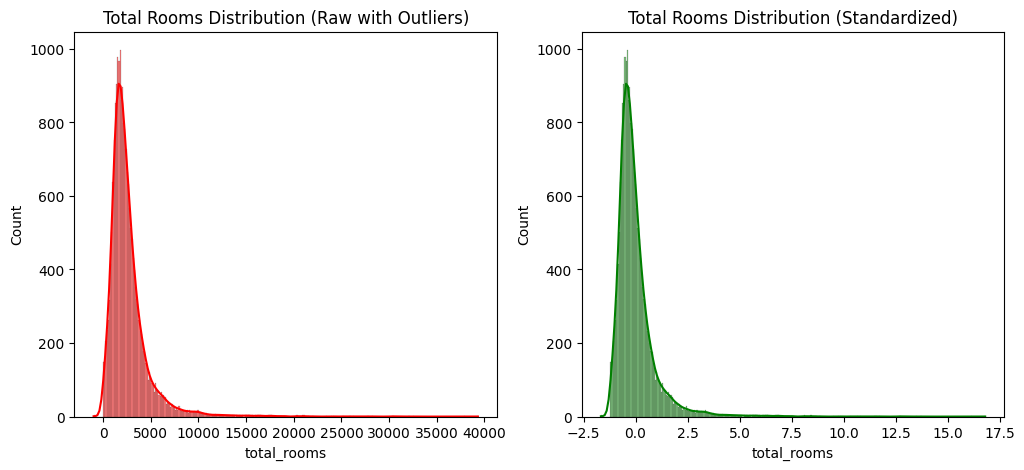

In [17]:
#17. Visualize the distribution of numerical features before and after preprocessing
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df_label['total_rooms'], kde=True, color='red')
plt.title('Total Rooms Distribution (Raw with Outliers)')

plt.subplot(1, 2, 2)
sns.histplot(df['total_rooms'], kde=True, color='green')
plt.title('Total Rooms Distribution (Standardized)')
plt.show()

In [19]:
print("18. Preprocessing Executive Summary")
print(f"Initial Dataset shape: (20640, 10)")
print(f"Final Dataset feature pool dimension: {X.shape}")
print("Adjustments performed: Treated structural anomalies, removed dirty records, parsed inconsistent object types, imputed missing values with column medians, and balanced features via SMOTE.")

18. Preprocessing Executive Summary
Initial Dataset shape: (20640, 10)
Final Dataset feature pool dimension: (20640, 14)
Adjustments performed: Treated structural anomalies, removed dirty records, parsed inconsistent object types, imputed missing values with column medians, and balanced features via SMOTE.


In [20]:
df.to_csv("cleaned_california_housing.csv", index=False)
print("File successfully saved as 'cleaned_california_housing.csv' inside your Colab runtime directory!")

File successfully saved as 'cleaned_california_housing.csv' inside your Colab runtime directory!
